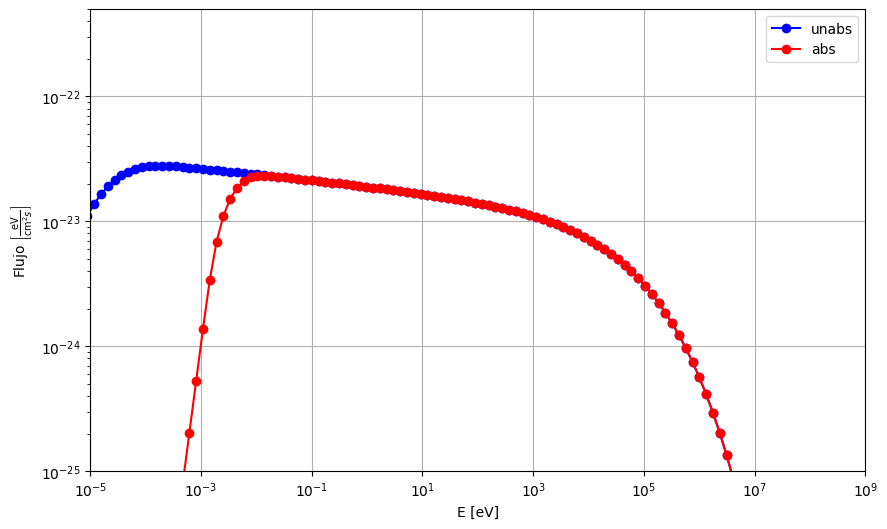

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def leer_archivo_texto(ruta_archivo):
    ''' Funcion que lee el un archivo y la convierte las filas a una lista de listas'''
    datos = []
    with open(ruta_archivo, 'r') as archivo:
        for linea in archivo:
            # Limpiar la línea y dividir en números
            numeros = linea.strip().split()
            
            # Convertir los números a enteros (o flotantes si lo prefieres)
            #if len(numeros) != 9:
            #    print(f"Advertencia: La línea no tiene 9 números: {linea.strip()}")
            #    continue
            
            numeros = [num for num in numeros]
            datos.append(numeros)
    
    return datos

#Pongo la distancia al sistema en cm
d=1.234e+25
# Ruta al archivo de texto
ruta_archivo = 'SEDe_syn_jet.dat'

# Llamar a la función para leer el archivo
datos = leer_archivo_texto(ruta_archivo)

#Convierto los datos del archivo de luminosidad a Flujo
for i, fila in enumerate(datos):
    fila[7]=str(float(fila[7])/((4*np.pi)*d*d))
    fila[8]=str(float(fila[8])/((4*np.pi)*d*d))
    

# Guardo los datos modificados en un nuevo archivo
with open('conversion.dat','w') as archivo:
    for i, fila in enumerate(datos):
        contenido = ', '.join(fila)
        archivo.write(contenido+'\n')


# Grafico
%matplotlib inline
df = pd.read_csv('conversion.dat')
# Crear el gráfico
plt.figure(figsize=(10, 6))
plt.plot(df.iloc[:, 0], df.iloc[:, 7]*1.6022e-12, label='unabs', marker='o', linestyle='-', color='b')
plt.plot(df.iloc[:, 0], df.iloc[:, 8]*1.6022e-12, label='abs', marker='o', linestyle='-', color='r')
plt.xlabel('E [eV]')
plt.ylabel(r'Flujo $\left[\frac{\text{eV}}{\text{cm}^2 s}\right]$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e-5,1e9)
plt.ylim(1e-25,5e-22)
plt.legend()
#plt.title('Gráfico de Columnas 1 y 8')
plt.grid(True)
plt.savefig('imagen1')
plt.show()



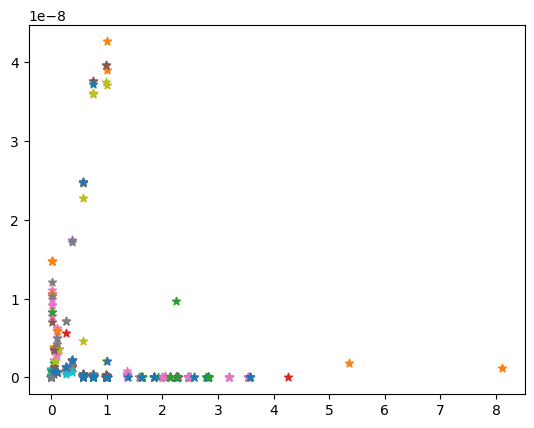

In [12]:
import pandas as pd
import glob
import os
pd.options.mode.chained_assignment = None 
def crear_dataframe(carpeta):
    '''Lee uno a uno los archivo de un dado directorio para graficar los contenidos como puntos de un plot'''
    dfs = []
    
    # Buscar todos los archivos en la carpeta
    archivos_dat = glob.glob(os.path.join(carpeta, '*'))
    for archivo in archivos_dat:
        #Leo uno a uno los archivos, la primer columna es innecesaria
        df = pd.read_csv(archivo, delimiter='\t', header=None, skiprows=1)
        # Selecciona las columnas 1 (Identificador de la observacion), 5 (Frecuencia obs), 6 (Long de onda) y 7 (Flujo)
        df_seleccionado = df.iloc[:, [0 ,4, 5, 6]]
        
        # Asigna nombres a las columnas
        df_seleccionado.columns = ['Observacion','Frecuencia_GHz', 'Longitud_onda_micrometros', 'Flujo_Jy']
        #Transforma las unidades
        df_seleccionado['Frecuencia_Hz']=df_seleccionado['Frecuencia_GHz']*1e9
        df_seleccionado['Energia_eV']=df_seleccionado['Frecuencia_Hz']*4.135667696e-15
        df_seleccionado['Flujo_ergs-1cm2']=df_seleccionado['Flujo_Jy']*df_seleccionado['Frecuencia_Hz']*1e-23
        #Tomo el nombre de cada archivo para identificar en la grafica
        observacion=archivo.split('.')
        observacion=observacion[0].split('/')#df_seleccionado['Observacion'][:]=df_seleccionado['Observacion'][:][:6]
        #Preparo los scatter para graficar las observaciones
        plt.scatter(df_seleccionado.iloc[:,5],df_seleccionado.iloc[:,6], marker='*', label=observacion[1])
    return  df_seleccionado



##Prueba rapida
# Crear el DataFrame
archivo='Observaciones'
#
df_resultado = crear_dataframe(archivo)

# Mostrar el DataFrame
#df_resultado['Frecuencia_Hz']=df_resultado['Frecuencia_GHz']*1e9
#df_resultado['Energia_eV']=df_resultado['Frecuencia_Hz']*4.135667696e-15
#df_resultado['Flujo_ergs-1cm2']=df_resultado['Flujo_Jy']*df_resultado['Frecuencia_Hz']*1e-23



#df_resultado



In [26]:
hex_colors

["'#4bb4ca'",
 "'#22cc92'",
 "'#67808e'",
 "'#46a3d3'",
 "'#70d824'",
 "'#3dad85'",
 "'#3b0f61'",
 "'#a95502'",
 "'#6a160f'",
 "'#ad4769'",
 "'#623c47'",
 "'#a95fd7'",
 "'#544418'",
 "'#40ac59'",
 "'#99a5bf'",
 "'#d5a9dc'",
 "'#7b2a25'",
 "'#f90aee'",
 "'#bbf5f3'",
 "'#37b404'",
 "'#a1e197'",
 "'#322571'",
 "'#3b5d7b'",
 "'#b45db9'",
 "'#abf5cf'",
 "'#e33f42'",
 "'#2430fb'",
 "'#358e17'",
 "'#f13af2'",
 "'#699213'",
 "'#2465ee'"]

In [15]:
import random
import matplotlib as mpl

def generate_hex_color():
    '''Funcion que genera una lista de colores aleatorios para diferenciar las observaciones'''
    return f'#{random.randint(0, 0xFFFFFF):06x}'

hex_colors = [generate_hex_color() for _ in range(31)]
hex_colors = [f"'{color}'" for color in hex_colors]
#hex_colors
#Edito el ciclo de colores de matplotlib para que en lugar de circular entre los colores por defecto (7 colores) circule entre la nueva lista
mpl.rcParams['axes.prop_cycle'] = mpl.cycler(color=hex_colors) 

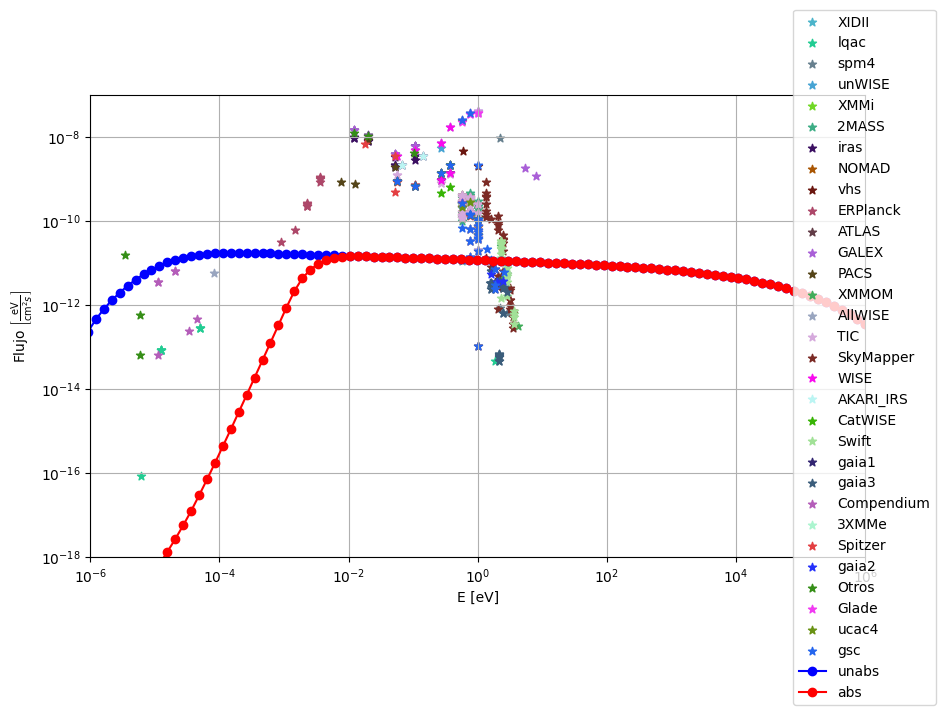

In [25]:
plt.figure(figsize=(10, 6))
crear_dataframe('Observaciones')
plt.plot(df.iloc[:, 0], df.iloc[:, 7], label='unabs', marker='o', linestyle='-', color='b')
plt.plot(df.iloc[:, 0], df.iloc[:, 8], label='abs', marker='o', linestyle='-', color='r')
plt.xlabel('E [eV]')
plt.ylabel(r'Flujo $\left[\frac{\text{eV}}{\text{cm}^2 s}\right]$')
plt.xscale('log')
plt.yscale('log')
plt.xlim(1e-6,1e6)
plt.ylim(1e-18,1e-7)
plt.legend(loc='upper right', bbox_to_anchor=(1, 1.1, 0.1,0.1))
#plt.title('Gráfico de Columnas 1 y 8')
plt.grid(True)
plt.savefig('imagenobs.png')
plt.show()
